In [42]:
# 예제 1

import numpy as np
import tensorflow as tf
import tensorflow.keras.datasets as ds

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dropout,Dense
from tensorflow.keras.optimizers import Adam

# 실행이 안될 시 Python 버전 점검 (TensorFlow가 Python 3.12를 지원하지 않으므로, Python 버전을 3.10 이하로 신규 가상 환경 생성 필요)
# conda create -n tf_env python=3.10
# conda activate tf_env

(x_train,y_train),(x_test,y_test)=ds.mnist.load_data()
x_train=x_train.reshape(60000,28,28,1)
x_test=x_test.reshape(10000,28,28,1)
x_train=x_train.astype(np.float32)/255.0
x_test=x_test.astype(np.float32)/255.0
y_train=tf.keras.utils.to_categorical(y_train,10)
y_test=tf.keras.utils.to_categorical(y_test,10)

cnn=Sequential()
cnn.add(Conv2D(6,(5,5),padding='same',activation='relu',input_shape=(28,28,1)))
cnn.add(MaxPooling2D(pool_size=(2,2),strides=2))
cnn.add(Conv2D(16,(5,5),padding='valid',activation='relu'))
cnn.add(MaxPooling2D(pool_size=(2,2),strides=2))
cnn.add(Conv2D(120,(5,5),padding='valid',activation='relu'))
cnn.add(Flatten())
cnn.add(Dense(units=84,activation='relu'))
cnn.add(Dense(units=10,activation='softmax'))

cnn.compile(loss='categorical_crossentropy',optimizer=Adam(learning_rate=0.001),metrics=['accuracy']) 
cnn.fit(x_train,y_train,batch_size=128,epochs=30,validation_data=(x_test,y_test),verbose=2)
                                    
res=cnn.evaluate(x_test,y_test,verbose=0) 
print('정확률=',res[1]*100)

Epoch 1/30
469/469 - 3s - 7ms/step - accuracy: 0.9034 - loss: 0.3244 - val_accuracy: 0.9689 - val_loss: 0.0976
Epoch 2/30
469/469 - 3s - 6ms/step - accuracy: 0.9731 - loss: 0.0890 - val_accuracy: 0.9813 - val_loss: 0.0604
Epoch 3/30
469/469 - 3s - 6ms/step - accuracy: 0.9805 - loss: 0.0630 - val_accuracy: 0.9854 - val_loss: 0.0457
Epoch 4/30
469/469 - 3s - 6ms/step - accuracy: 0.9848 - loss: 0.0481 - val_accuracy: 0.9888 - val_loss: 0.0381
Epoch 5/30
469/469 - 3s - 7ms/step - accuracy: 0.9878 - loss: 0.0387 - val_accuracy: 0.9889 - val_loss: 0.0342
Epoch 6/30
469/469 - 3s - 7ms/step - accuracy: 0.9892 - loss: 0.0331 - val_accuracy: 0.9891 - val_loss: 0.0360
Epoch 7/30
469/469 - 3s - 7ms/step - accuracy: 0.9902 - loss: 0.0297 - val_accuracy: 0.9882 - val_loss: 0.0365
Epoch 8/30
469/469 - 3s - 7ms/step - accuracy: 0.9919 - loss: 0.0234 - val_accuracy: 0.9888 - val_loss: 0.0325
Epoch 9/30
469/469 - 3s - 7ms/step - accuracy: 0.9930 - loss: 0.0204 - val_accuracy: 0.9863 - val_loss: 0.0438
E

In [43]:
import os
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Keras 데이터 경로:", os.path.expanduser("~/.keras/datasets"))

TensorFlow: 2.21.0
Keras 데이터 경로: /Users/pitzsb1/.keras/datasets


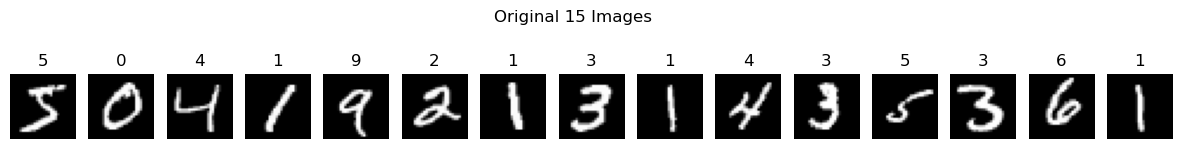

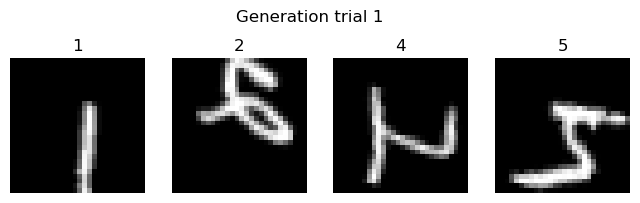

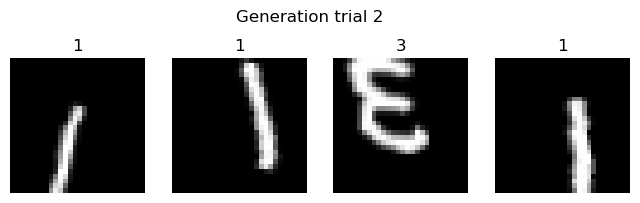

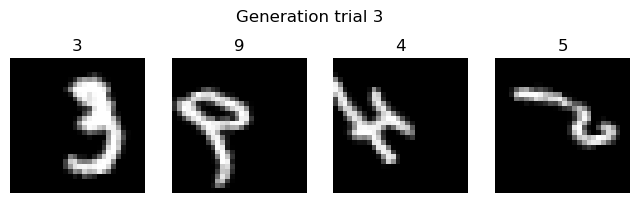

In [44]:
# 예제 2 (시간 이슈로 간소화)

import numpy as np
import tensorflow.keras.datasets as ds
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt

# 이미 다운로드된 MNIST 사용
(x_train, y_train), (x_test, y_test) = ds.mnist.load_data()

x_train = x_train[:15].astype('float32') / 255.0
y_train = y_train[:15]

# 이미지 채널 추가
x_train = x_train.reshape(15, 28, 28, 1)

# 원본 이미지 출력
plt.figure(figsize=(15, 2))
plt.suptitle("Original 15 Images")

for i in range(15):
    plt.subplot(1, 15, i + 1)
    plt.imshow(x_train[i, :, :, 0], cmap='gray')
    plt.title(str(y_train[i]))
    plt.axis('off')

plt.show()

# 데이터 증강
batch_siz = 4

generator = ImageDataGenerator(
    rotation_range=20.0,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

gen = generator.flow(
    x_train,
    y_train,
    batch_size=batch_siz
)

# 증강된 이미지 출력
for a in range(3):
    img, label = next(gen)

    plt.figure(figsize=(8, 2.4))
    plt.suptitle("Generation trial " + str(a + 1))

    for i in range(batch_siz):
        plt.subplot(1, batch_siz, i + 1)
        plt.imshow(img[i, :, :, 0], cmap='gray')
        plt.title(str(label[i]))
        plt.axis('off')

    plt.show()

Found 20580 files belonging to 120 classes.
Using 16464 files for training.
Found 20580 files belonging to 120 classes.
Using 4116 files for validation.
Epoch 1/3
10/10 - 7s - 743ms/step - accuracy: 0.0250 - loss: 6.2472 - val_accuracy: 0.0000e+00 - val_loss: 5.5912
Epoch 2/3
10/10 - 1s - 137ms/step - accuracy: 0.0500 - loss: 5.0291 - val_accuracy: 0.0417 - val_loss: 4.8073
Epoch 3/3
10/10 - 2s - 154ms/step - accuracy: 0.0875 - loss: 4.4118 - val_accuracy: 0.0000e+00 - val_loss: 4.7789
정확률 = 0.0 %
모델 저장 완료: /Users/pitzsb1/computer-vision-practice/cnn_for_stanford_dogs.keras
견종 이름 저장 완료: /Users/pitzsb1/computer-vision-practice/dog_species_names.txt


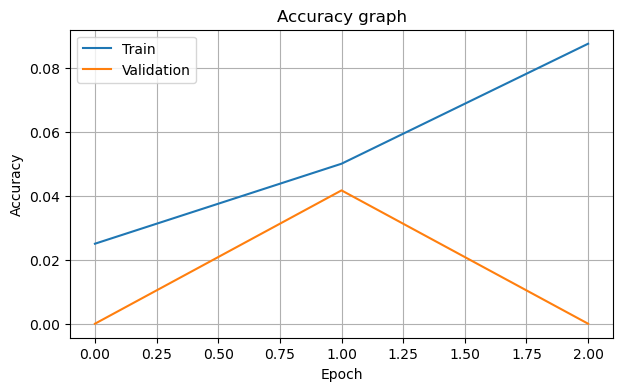

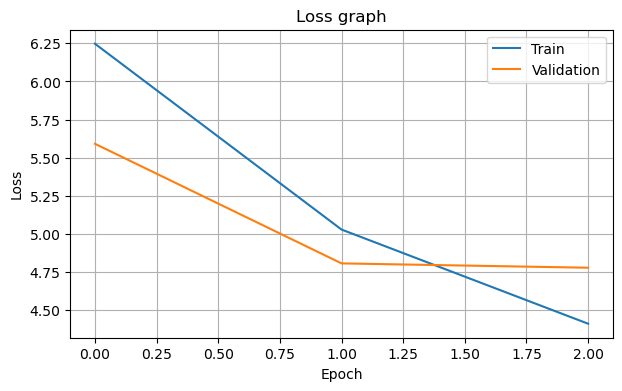

In [45]:
# 예제 3 (시간 이슈로 간소화)

import os
import pathlib
import pickle
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications.densenet import DenseNet121, preprocess_input
from tensorflow.keras.utils import image_dataset_from_directory

# 1. 데이터셋 및 저장 경로
data_path = pathlib.Path(
    '/Users/pitzsb1/computer-vision-practice/ch8/datasets/standford_dogs/Images'
)

save_dir = os.path.expanduser('~/computer-vision-practice')
os.makedirs(save_dir, exist_ok=True)

# 2. 데이터셋 불러오기
train_ds = image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset='training',
    seed=123,
    image_size=(128, 128),
    batch_size=8
)

test_ds = image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset='validation',
    seed=123,
    image_size=(128, 128),
    batch_size=8
)

# 클래스 이름 저장
class_names = train_ds.class_names

# 3. 학습 시간 단축을 위해 일부 데이터만 사용
train_ds = train_ds.take(10).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.take(3).prefetch(tf.data.AUTOTUNE)

# 4. 사전 학습된 DenseNet121 불러오기
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

# 기존 가중치 동결
base_model.trainable = False

# 5. 모델 구성
inputs = Input(shape=(128, 128, 3))

x = preprocess_input(inputs)
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

outputs = Dense(
    len(class_names),
    activation='softmax'
)(x)

cnn = Model(inputs, outputs)

# 6. 모델 컴파일
cnn.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)

# 7. 모델 학습
hist = cnn.fit(
    train_ds,
    epochs=3,
    validation_data=test_ds,
    verbose=2
)

# 8. 정확도 평가
accuracy = cnn.evaluate(test_ds, verbose=0)[1] * 100
print('정확률 =', accuracy, '%')

# 9. 모델 저장 (읽기 전용 오류 해결)
model_path = os.path.join(
    save_dir,
    'cnn_for_stanford_dogs.keras'
)

cnn.save(model_path)
print('모델 저장 완료:', model_path)

# 10. 견종 이름 저장
names_path = os.path.join(
    save_dir,
    'dog_species_names.txt'
)

with open(names_path, 'wb') as f:
    pickle.dump(class_names, f)

print('견종 이름 저장 완료:', names_path)

# 11. 정확도 그래프
plt.figure(figsize=(7, 4))

plt.plot(hist.history['accuracy'], label='Train')
plt.plot(hist.history['val_accuracy'], label='Validation')

plt.title('Accuracy graph')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.grid()
plt.show()

# 12. 손실 그래프
plt.figure(figsize=(7, 4))

plt.plot(hist.history['loss'], label='Train')
plt.plot(hist.history['val_loss'], label='Validation')

plt.title('Loss graph')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid()
plt.show()

In [55]:
# 실습

import os
import pickle
import tkinter as tk
from tkinter import filedialog, messagebox

import numpy as np
import tensorflow as tf

from PIL import Image, ImageTk, ImageDraw, ImageFont

# =====================================================
# 1. 저장된 모델 불러오기
# =====================================================

save_dir = os.path.expanduser("~/computer-vision-practice")

model_path = os.path.join(
    save_dir, "cnn_for_stanford_dogs.keras"
)

names_path = os.path.join(
    save_dir, "dog_species_names.txt"
)

# 학습 모델에 따라 변경 필요: 모델 파일 경로
cnn = tf.keras.models.load_model(model_path, compile=False)

# 학습 모델에 따라 변경 필요: 견종 클래스 이름
with open(names_path, "rb") as f:
    class_names = pickle.load(f)

print("모델 로딩 완료!")
print("견종 수:", len(class_names))


# =====================================================
# 2. 견종 인식 함수
# =====================================================

selected_image = None


def open_image():
    global selected_image

    file_path = filedialog.askopenfilename(
        title="강아지 사진 선택",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png"),
            ("All files", "*.*")
        ]
    )

    if not file_path:
        return

    selected_image = Image.open(file_path).convert("RGB")

    show_image(selected_image)
    result_label.config(text="사진 선택 완료! 품종 인식을 눌러주세요.")


def predict_dog():
    if selected_image is None:
        messagebox.showwarning(
            "알림",
            "먼저 강아지 사진을 선택하세요."
        )
        return

    # 학습 모델에 따라 변경 필요:
    # 간소화 모델은 128x128 이미지 사용
    input_size = (128, 128)

    img = selected_image.resize(input_size)

    # 학습 모델에 따라 변경 필요:
    # 간소화 모델 내부에서 preprocess_input 수행
    # 따라서 외부에서는 255로 나누지 않음
    img_array = np.array(img, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)

    predictions = cnn.predict(img_array, verbose=0)[0]

    top5 = np.argsort(predictions)[::-1][:5]

    result_lines = []

    for rank, idx in enumerate(top5, start=1):
        name = class_names[idx]
        probability = predictions[idx] * 100

        result_lines.append(
            f"{rank}. {name}: {probability:.2f}%"
        )

    result_label.config(
        text="\n".join(result_lines)
    )

    # 사진 위에도 추론 결과 표시
    result_image = selected_image.copy()
    result_image.thumbnail((700, 500))

    draw = ImageDraw.Draw(result_image)

    # 글자 배경
    draw.rectangle(
        (0, 0, result_image.width, 125),
        fill=(0, 0, 0)
    )

    for i, line in enumerate(result_lines):
        draw.text(
            (10, 10 + i * 23),
            line,
            fill="white"
        )

    show_image(result_image)


# =====================================================
# 3. 이미지 표시 함수
# =====================================================

def show_image(image):
    img = image.copy()
    img.thumbnail((700, 500))

    photo = ImageTk.PhotoImage(img)

    image_label.config(image=photo)
    image_label.image = photo


# =====================================================
# 4. GUI 구성
# =====================================================

root = tk.Tk()
root.title("견종 인식 에이전트")
root.geometry("800x750")

title_label = tk.Label(
    root,
    text="DenseNet121 견종 인식 에이전트",
    font=("Arial", 18, "bold")
)
title_label.pack(pady=15)

button_frame = tk.Frame(root)
button_frame.pack(pady=10)

open_button = tk.Button(
    button_frame,
    text="강아지 사진 열기",
    command=open_image,
    width=18
)
open_button.pack(side=tk.LEFT, padx=5)

predict_button = tk.Button(
    button_frame,
    text="품종 인식",
    command=predict_dog,
    width=18
)
predict_button.pack(side=tk.LEFT, padx=5)

exit_button = tk.Button(
    button_frame,
    text="나가기",
    command=root.destroy,
    width=12
)
exit_button.pack(side=tk.LEFT, padx=5)

image_label = tk.Label(root)
image_label.pack(pady=15)

result_label = tk.Label(
    root,
    text="강아지 사진을 선택하세요.",
    font=("Arial", 12),
    justify=tk.LEFT
)
result_label.pack(pady=10)

root.mainloop()

모델 로딩 완료!
견종 수: 120
